# P281 Homework Set 3
2026-10-29 hw3_10_29.ipynb Bella K

In [1]:
import numpy as np
from numpy import pi, sqrt, cos, sin, exp
import matplotlib.pyplot as plt
import pandas as pd
import scipy

### Question 1
A circuit of resistors

@ V1: 4V1 - V2 - V3 - V4 = V+

for the other three junctions:

@ V2: (V2 - 0V)/R + (V2 - V4)/R + (V2 - V1)/R = 0

3V2 - V4 - V1 = 0

@ V3: (V3 - V+)/R + (V3 - V1)/R + (V3 - V4)/R = 0

3V3 - V1 - V4 = V+

@ V4: (V4 - V3)/R + (V4 - V1)/R + (V4 - V2)/R + (V4 - 0V)/R = 0

4V4 - V3 - V1 - V2 = 0

In [2]:
volt_mat = np.array(((4, -1, -1, -1),
                     (-1, 3, 0, -1),
                     (-1, 0, 3, -1),
                     (-1, -1, -1, 4)))
rhs = np.array((5, 0, 5, 0))

sols = np.linalg.solve(volt_mat, rhs)

print('voltages v1-v4:', sols)

voltages v1-v4: [3.         1.66666667 3.33333333 2.        ]


### Question 2
Rotate the galaxy

In [3]:
gal2 = pd.read_csv('galaxy2.txt', sep = r'\s+')

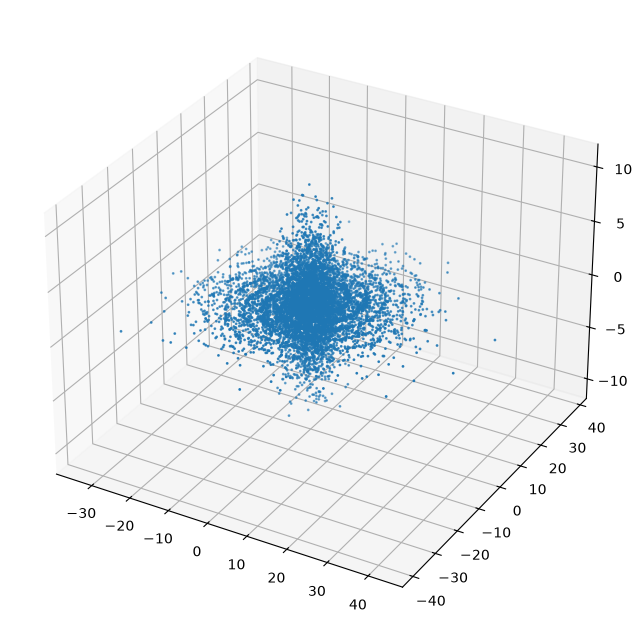

In [4]:
# image w/o rotation
fig = plt.figure(figsize = (10, 8))
ax = fig.add_subplot(projection = '3d')

sc = ax.scatter(gal2['x(kpc)'], gal2['y(kpc)'], gal2['z(kpc)'], s = 1)

In [5]:
def rmat(theta,nhat):
    """Returns 3D rotation matrix thru theta(rad) about unit vector nhat"""
    return scipy.linalg.expm(np.cross(np.eye(3),nhat*theta))

In [6]:
rmat_xy = rmat(np.pi/100, np.array((1,1,0)))

In [7]:
rot_arr = np.zeros((len(gal2), 3))

for i in range(len(gal2)):
    rot_arr[i] = (np.matmul(rmat_xy, (gal2['x(kpc)'][i], gal2['y(kpc)'][i], gal2['z(kpc)'][i])))

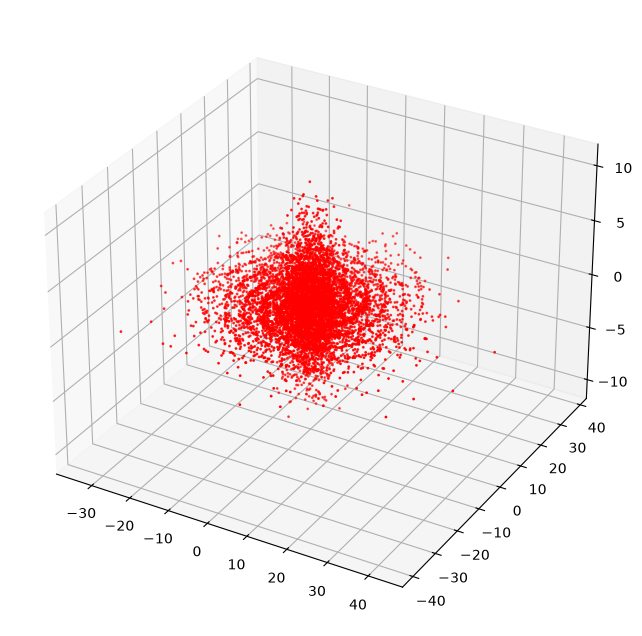

In [8]:
# image w rotation
fig = plt.figure(figsize = (10, 8))
ax = fig.add_subplot(projection = '3d')

sc = ax.scatter(rot_arr[:, 0], rot_arr[:, 1], rot_arr[:, 2], s = 1, c = 'r')

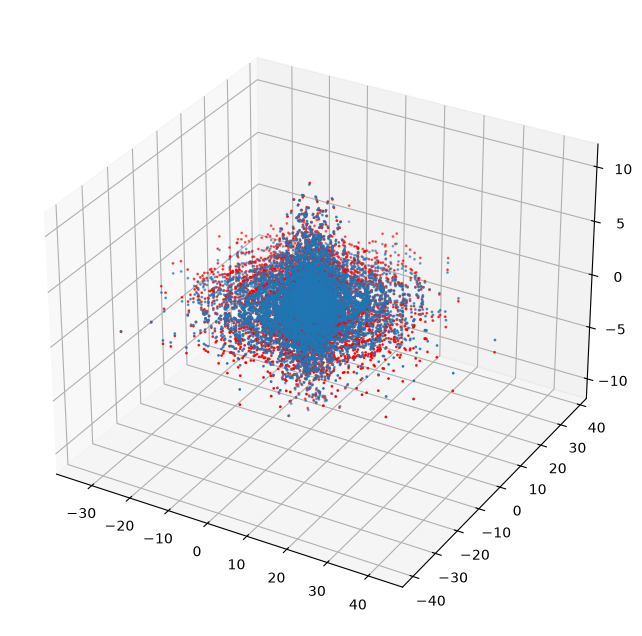

In [9]:
# both images
fig = plt.figure(figsize = (10, 8))
ax = fig.add_subplot(projection = '3d')

sc = ax.scatter(gal2['x(kpc)'], gal2['y(kpc)'], gal2['z(kpc)'], s = 1)
sc = ax.scatter(rot_arr[:, 0], rot_arr[:, 1], rot_arr[:, 2], s = 1, c = 'r')

### Question 3
Use complex numbers to analyze an AC circuit

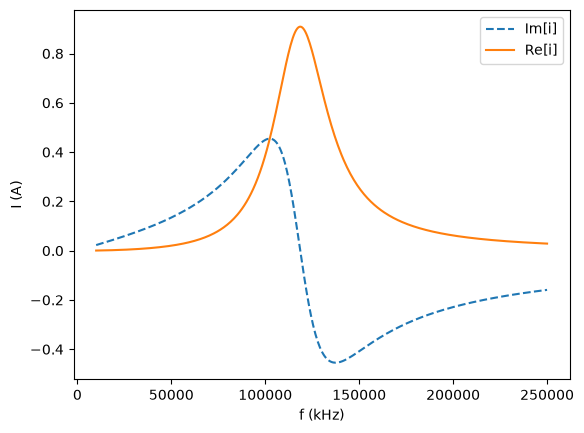

In [10]:
rr = 33
ll = 150e-6
cc = 12e-9
vv = 30

ws = np.linspace(2*np.pi*10e3, 2*np.pi*250e3, 400)
fs = ws / (2*np.pi)

zz_l = 1j * ws * ll
zz_c = 1 / (1j * ws * cc)
zz_t = rr + zz_l + zz_c

ii = vv / zz_t

plt.plot(fs, np.imag(ii), label = 'Im[i]', linestyle = '--')
plt.plot(fs, np.real(ii), label = 'Re[i]')
plt.xlabel('f (kHz)')
plt.ylabel('I (A)')
plt.legend()
plt.show()

### Question 4
A bit of solid state physics: Chain of atoms

for two masses and three springs:
alpha * [X_1, X_2] = [2, -1,
                      -1, 2] * [X_1, X_2]

for four masses and five springs:
alpha * [X_1, X_2, X_3, X_4] = [2, -1, 0, 0, 
                                -1, 2, -1, 0,
                                0, -1, 2, -1
                                0, 0, -1, 2] * [X_1, X_2, X_3, X_4]

In [11]:
nn = int(input('Value for N? '))

def norm_mode_mat(nn):
    aa = np.zeros((nn, nn))
    aa = aa + 2 * np.eye(nn)

    for i in range(len(aa)):
        if i + 1 < len(aa):
            aa[i, i + 1] = -1
        if i - 1 >= 0:
            aa[i, i - 1] = -1
            
    return aa

aa = norm_mode_mat(nn)
print(f'N = {nn}, \nA = {aa}')

N = 10, 
A = [[ 2. -1.  0.  0.  0.  0.  0.  0.  0.  0.]
 [-1.  2. -1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0. -1.  2. -1.  0.  0.  0.  0.  0.  0.]
 [ 0.  0. -1.  2. -1.  0.  0.  0.  0.  0.]
 [ 0.  0.  0. -1.  2. -1.  0.  0.  0.  0.]
 [ 0.  0.  0.  0. -1.  2. -1.  0.  0.  0.]
 [ 0.  0.  0.  0.  0. -1.  2. -1.  0.  0.]
 [ 0.  0.  0.  0.  0.  0. -1.  2. -1.  0.]
 [ 0.  0.  0.  0.  0.  0.  0. -1.  2. -1.]
 [ 0.  0.  0.  0.  0.  0.  0.  0. -1.  2.]]


In [12]:
evals = scipy.linalg.eigvalsh(aa)
evals_test, evecs_test = scipy.linalg.eigh(aa)
print(f'With linalg.eigvalsh, eigenvalues:\n{evals}')
print(f'With linalg.eigh, eigenvalues:\n{evals_test}')

With linalg.eigvalsh, eigenvalues:
[0.08101405 0.31749293 0.69027853 1.16916997 1.71537032 2.28462968
 2.83083003 3.30972147 3.68250707 3.91898595]
With linalg.eigh, eigenvalues:
[0.08101405 0.31749293 0.69027853 1.16916997 1.71537032 2.28462968
 2.83083003 3.30972147 3.68250707 3.91898595]


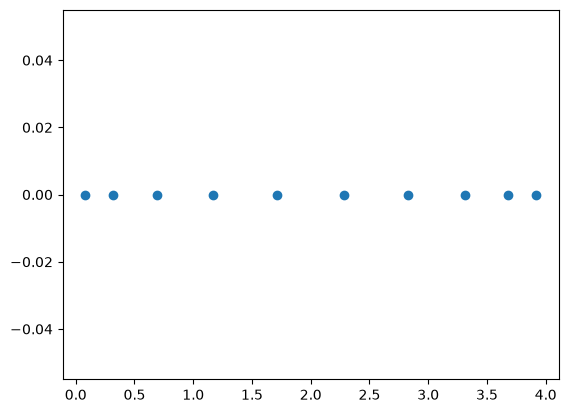

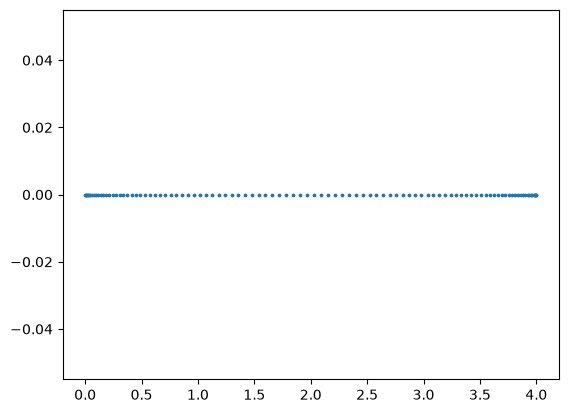

In [13]:
# for nn = 10
plt.scatter(evals, np.zeros(len(evals)))
plt.show()

# for nn = 100
aa_100 = norm_mode_mat(100)
evals_100 = scipy.linalg.eigvalsh(aa_100)
plt.scatter(evals_100, np.zeros(len(evals_100)), s =3)
plt.show()

There are now 100 eigenvalues instead of 10, and they span the same space, so the density of the eigenvalues increases greatly. The trend of the eigenvalues 'bunching up' towards the ends of 0-4 continues.

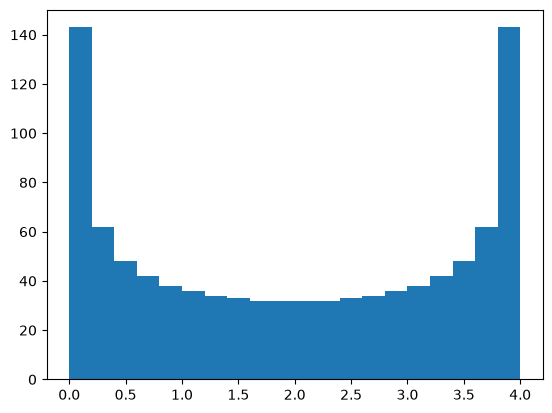

In [14]:
# for nn = 1000
aa_1e3 = norm_mode_mat(1000)
evals_1e3 = scipy.linalg.eigvalsh(aa_1e3)
plt.hist(evals_1e3, bins = 20)
plt.show()